<div style="background:#F9F1DB;border-top:4px solid #ECD594;padding:12px 16px;color:#292722;font-family:monospace;font-size:12px;letter-spacing:0.06em;">
GEOSTATISTICS LESSONS · DATA TRANSFORMATION · COMPANION NOTEBOOK
</div>

# Trend Modeling and Modeling with a Trend

**Sebastian Sanchez, Ben Harding and Ryan Barnett**

Notebook published: October 10, 2024

[Read the lesson](https://geostatisticslessons.com/lessons/trendmodeling) · [Notebook guide](README.md)

## Learning Objectives

- Review the concepts of stationarity
- Appreciate trend modeling and modeling with a trend
- Demonstrate the importance of trend modeling in modern geostatistical workflows
- Understand the techniques and checks implemented.

## Overview

The following notebook accompanies the lesson [Trend Modeling and Modeling with a Trend](https://geostatisticslessons.com/lessons/trendmodeling). The following steps are used for demonstrating the modern approach for modeling in presence of a trend, applying the same data from the lesson and applying minor refinements/additions.

1. **Load data**
    - Load and inspect data before defining a grid
1. **Normal score transformation and variography**
    - A normal score transform is not explicitly required prior to trend modeling, but generally improves behaviour of trend smoothing metrics, as well as Gaussian mixture model (GMM) fitting (used for trend removal)
    - Variography is performed on the normal scores to inform anisotropy of the moving window average (MWA) used for trend estimation
1. **Trend modeling**
    - Determine the optimal MWA smoothing parameters before estimating the normal scores trend over the grid
1. **Detrending transformation and variography**
    - Remove the trend from the normal scores using a stepwise conditional transformation with GMM parameterization
    - Variography is performed on the detrended variable to parameterize the continuity that is input to simulation
1. **Simulation**
    - Simulate the detrended variable before visualizing the results
1. **Back-transform**
    - Restore the trend, then reverse the normal-score transformation to original units
1. **Checking**
    - Check the realizations for reproduction of the histogram, variogram, trend and visual characteristics

Although executed on a small 2D dataset for ease of understanding, the presented workflow may be extended/adapted to represent other deposits.

In [1]:
import platform
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rmsp

rmsp.activate(verbose=False)
rmsp.GlobalParams["plotting.viewer3d.dpi"] = 110
rmsp.GlobalParams["core.log_progress"] = False
rmsp.GlobalParams["plotting.viewer3d.show_static"] = True


%matplotlib inline

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "text.color": "#292722",
        "axes.labelcolor": "#292722",
        "axes.edgecolor": "#292722",
        "font.size": 11,
    }
)

# Start the kernel from the repository root, alongside the data/ folder.
DATA_DIR = Path.cwd() / "data"
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Start this notebook from the repository root, which contains data/."
    )

print(f"Python {platform.python_version()}")
print(
    " · ".join(
        f"{name} {version(name)}" for name in ["numpy", "pandas", "matplotlib", "rmsp"]
    )
)

Python 3.12.7
numpy 1.26.4 · pandas 2.1.4 · matplotlib 3.9.2 · rmsp 1.18.2


Activate RMSP and setup some global parameters:

In [2]:
log_progress = False  # Set to true for progressbars on intensive tasks
rmsp.GlobalParams["core.log_progress"] = log_progress
rmsp.GlobalParams["core.enable_beta"] = True
rmsp.GlobalParams["plotting.grid"] = True

Setup some coloring/naming parameters:

In [3]:
var = rmsp.Variable("Value").set_variable_params(clim=(0.9, 3.6), cmap="viridis")
ns_var = rmsp.Variable("NS_" + var.col).set_variable_params(
    clim=(-2, 2), axis_lim=(-3, 3), cmap="Spectral_r"
)
dt_var = ns_var.clone("DT_" + var.col)

---

## Load Data

Load example data that was used in the Lesson:

In [4]:
samples = rmsp.PointData(
    pd.read_csv(DATA_DIR / "trendmodeling_samples.csv"), x="X", y="Y"
)
samples.head()

,X,Y,wts,Value
0,4.498,6.141,0.98,1.209
1,29.803,3.799,0.90,1.511
2,50.928,5.057,0.84,1.861
3,73.395,5.370,0.90,2.531
4,93.624,3.186,0.94,2.075


Visualize the samples values and declustering weights. For more information about declustering, please take a look at the lesson [Cell Declustering Parameter Selection](https://geostatisticslessons.com/lessons/celldeclustering), although nearest neighbour or inverse distance are often preferred for capturing the geometry of domains to be simulated, and/or appropriately managing soft boundaries.

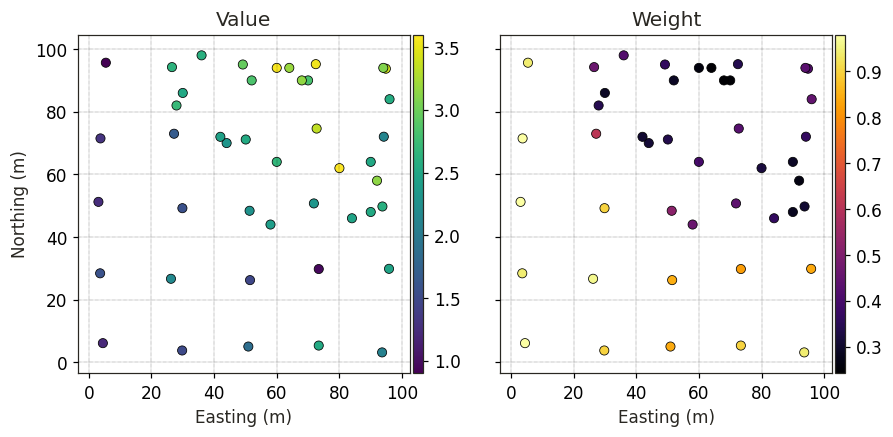

In [5]:
fig, axes = rmsp.ImageGrid(1, 2, figsize=(9, 4), cbar_mode="each", axes_pad=(0.7, 0.4))
samples.sectionplot(var.col, ax=axes[0], ec="k")
samples.sectionplot("wts", ax=axes[1], ec="k", cmap="inferno", title="Weight")

Define a grid for trend modeling and simulation, matching the grid used in the lesson:

In [6]:
griddef = rmsp.GridDef(
    usize=1.0,
    vsize=1.0,
    zsize=1.0,
    xcmin=0.5,
    ycmin=0.5,
    zcmin=0.5,
    nu=100,
    nv=100,
    nz=1,
    blockindices="full",
)
grid = rmsp.GridData(griddef=griddef)
griddef.to_table()

,Easting,Northing
minimum (m),0.00,0.00
maximum (m),100.00,100.00
size (m),1.00,1.00
number,100,100


---
## Normal Score Transformation and Variography

### Transformation
The details of the normal score transformation can be found in the lesson [Transforming Data to a Gaussian Distribution](https://geostatisticslessons.com/lessons/normalscore). Normal score transformation is a prerequisite for the Gaussian-mixture and conditional-transform workflow demonstrated here; it is not required for trend modeling generally.

Spatially despike tied grades before fitting the weighted normal score transform. The fixed seed makes tie-breaking reproducible; the original sample grades are retained for validation and back-transformation checks.

In [7]:
despiked = rmsp.DespikeSpatial(seed=515151).fit_transform(samples, var.col)
nscore = rmsp.NSTransformer()
samples[ns_var.col] = nscore.fit_transform(despiked, samples["wts"])

### Variography

Experimental variogram calculation and modeling: The lag parameters (spacing, tolerance and number of lags) are defined for experimental variograms calculation. The searches are defined using the lags and specified major/minor directions that are understood in this instance. Variography is wrapped in a function to permit re-use in detrended units.

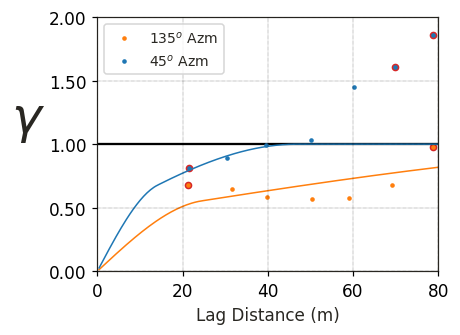

In [8]:
major, minor = 135, 45


def calc_model_varios(
    var, xlim=(0, 80), ylim=(0, 1.2), azmtol=25, num_struct=3, plot=True
):
    # Experimental
    lags = [rmsp.Lags(5, 5, 2), rmsp.Lags(10, 7.5, 10)]
    searches = [
        rmsp.ExpVarioSearch(azm, 0.0, lags, azmtol=azmtol) for azm in [major, minor]
    ]
    expvario = rmsp.ExpVario().calculate(samples, var, searches)
    # Model
    variomodel = rmsp.VarioModel.fit_experimental(
        expvario,
        num_struct=num_struct,
        nugget=0.0,
        shapes=["spherical"] * num_struct,
        angle1=[major] * num_struct,
        angle2=[0.0] * num_struct,
        angle3=[0.0] * num_struct,
        range1=[[20, 500]] * num_struct,
        ranges12_bounds=[[1.5, 4]] * num_struct,
    )
    # Plot
    if plot:
        fig, ax = variomodel.plot(
            azm=major, incl=0.0, c="C1", xlim=xlim, ylim=ylim, figsize=(4, 3)
        )
        expvario.plot_draw(ax=ax, azm=major, c="C1", label=f"{major}$^o$ Azm")
        variomodel.plot_draw(ax=ax, azm=minor, incl=0.0, c="C0")
        expvario.plot_draw(ax=ax, azm=minor, c="C0", label=f"{minor}$^o$ Azm")
        _ = ax.legend(fontsize="small")
    return expvario, variomodel


expvario, variomodel = calc_model_varios(ns_var.col, ylim=(0, 2.0))

---

## Trend Modeling

The search from trend modeling is obtained by buffering the variogram model. Search is based on the square root of anisotropy, following Qu (2018) recommendations:

In [9]:
trend_search = rmsp.Search.from_vario_buffer(
    variomodel,
    buffer_by=100,
    min_comps=1,
    scale_aniso="sqrt",
)

Select number of composites by testing different number of max composites and plotting against the trend-residual correlation. The composite number at the minimum trend-residual correlation is scaled using a factor of 2.0 following Qu (2018), although that criterion is sometimes found to oversmooth (or undersmooth) in practice, so careful visual inspection is always recommended, adjusting from its baseline guidance if needed.

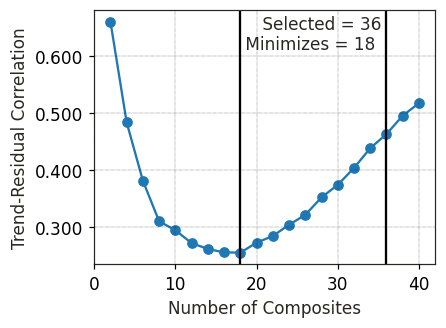

In [10]:
trend_est = rmsp.TrendEstimator(trend_search, sum_to_unity=False)
trend_est.minimize_residual_corr(
    samples, ns_var.col, scale_factor=2.0, test_min=2, test_max=40, test_inc=2
)
fig, ax = trend_est.plot_residual_corr(figsize=(4, 3), xlim=(0, 42))

Estimate trend across the grid:

In [11]:
trend = trend_est.estimate(grid, samples, ns_var.col)

Visualize trend:

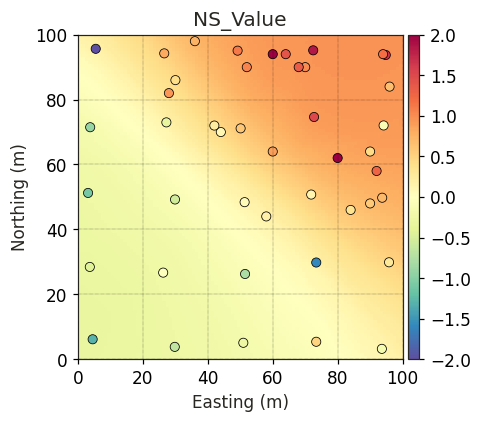

In [12]:
fig, ax, cax = trend.sectionplot(ns_var.col, figsize=(4, 4))
_ = samples.sectionplot_draw(ax=ax, var=ns_var.col, ec="k")

---
## Detrending Transformation and Variography

### Transformation
The RMSP function `TrendTransformer` does all the necessary steps for detrending:

1. Extract trend values at data locations
1. Fit GMM to the bivariate variable-trend relationship
1. GMM-SCT decorrelation of the bivariate variable-trend relationship to produce residuals that are assumed to be first-order stationary

These steps are achieved with the following `fit` and `transform` calls.

**Note** that the `fit_exhaustive` may struggle to converge with larger grids (e.g., >1M) - consider setting `fit_exhaustive` to False and providing declustering `weights` in those cases.

In [13]:
trend_transformer = rmsp.TrendTransformer(fit_exhaustive=True)
trend_transformer.fit(trend, samples, ns_var.col, num_kernels=2)

samples[dt_var.col] = trend_transformer.transform(trend, samples, ns_var.col)

Visualize the relationship and fit GMM:

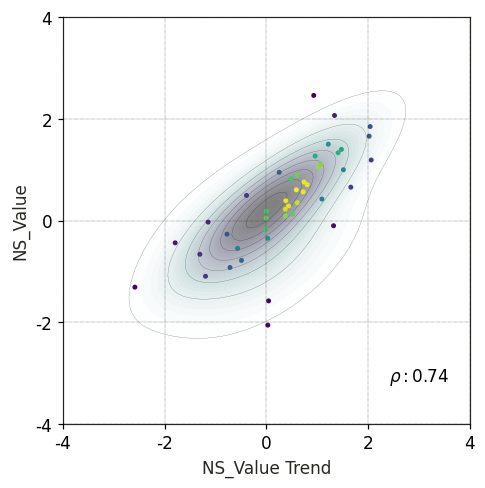

In [14]:
_ = trend_transformer.bivplots(trend, samples, scatplot_kws={"s": 5})

Visualize residuals and trend correlation after de-trending:

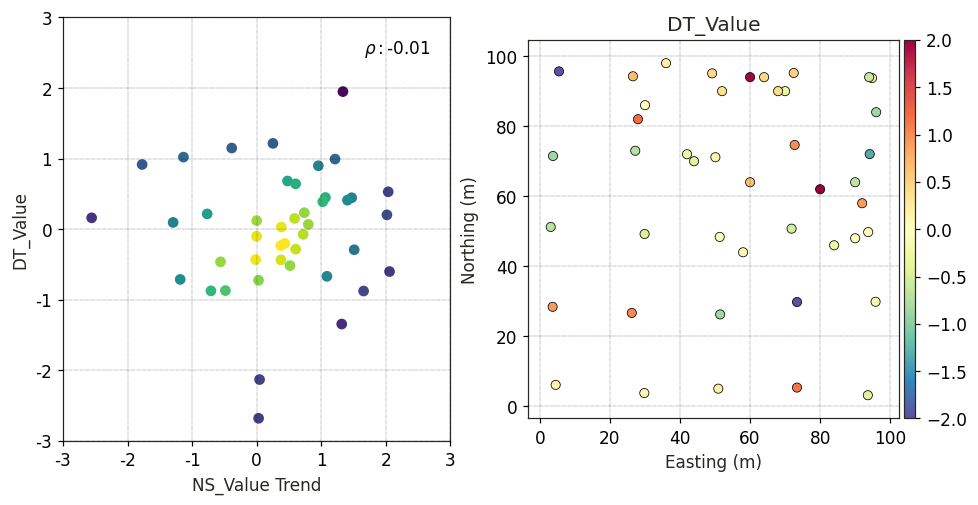

In [15]:
dt_var.clone(f"{dt_var} Trend")
samples[f"{ns_var} Trend"] = trend_transformer.get_transformed_trend(
    ns_var.col, samples
)[f"{ns_var} trend"]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
_ = samples.scatplot(f"{dt_var} Trend", dt_var.col, wt="wts", ax=axes[0])
samples.sectionplot(dt_var.col, ec="k", ax=axes[1])

### Variography

Calculate directional variograms of the detrended values at 135° and 45°, using a widened 50° azimuth tolerance to improve stability with these sparse data. Fit an anisotropic one-structure model with its major direction fixed at 135° and a major/minor range ratio constrained between 1.5 and 4. Detrending is expected to reduce but not remove the anisotropy observed in original or normal-score units.

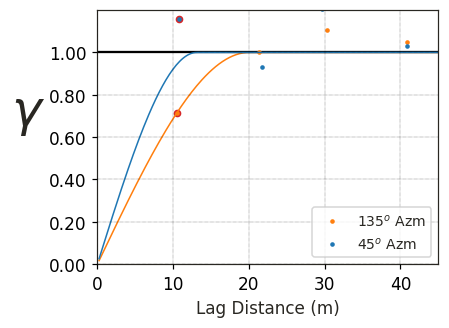

In [16]:
dt_variomodel = calc_model_varios(dt_var.col, xlim=(0, 45), azmtol=50, num_struct=1)[1]

---

## Simulation

The number of realizations to simulate:

In [17]:
num_real = 100

Conditional simulation is performed below. Notice that the variograms used in the simulation come from the detrended residuals:

In [18]:
simcache = rmsp.Simulator().simulate(
    grid,
    samples,
    dt_var.col,
    rmsp.Search.from_vario_buffer(dt_variomodel, max_comps=30),
    dt_variomodel,
    reals=num_real,
    seed=9897154,
    cache=None,
    cache_var=dt_var.col,
)

Visualize some realizations of the detrended variable. Wrap in a function to visualize after each back-transform.

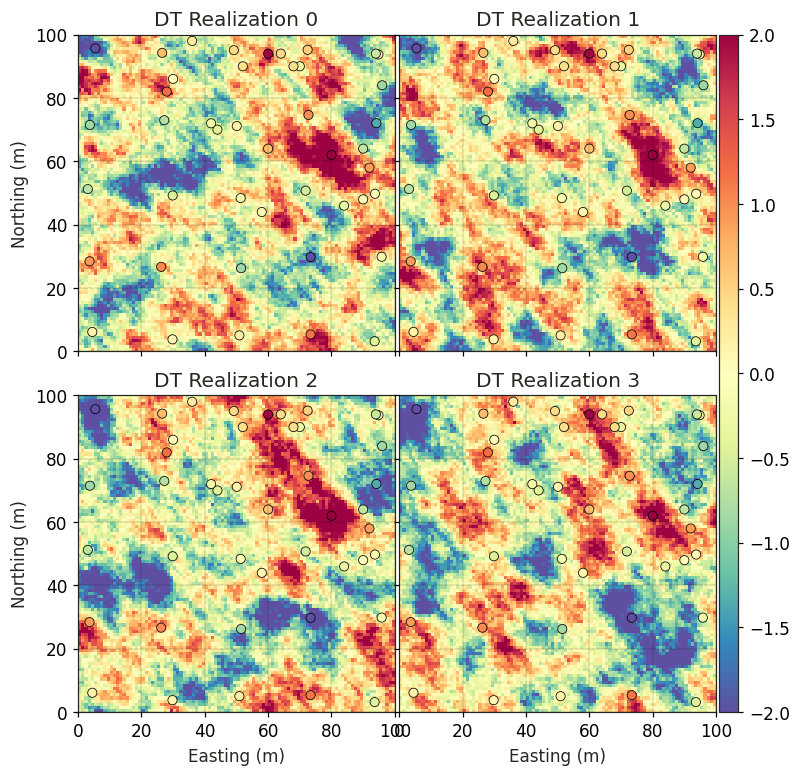

In [19]:
def plot_realizations(simcache, var, title_prefix=""):
    """Plots the first 4 realizations"""
    fig, axes = rmsp.ImageGrid(2, 2, (8, 8), cbar_mode="single")
    for i, real in simcache.iter_realizations(reals=4, griddef=griddef):
        real.sectionplot(var, ax=axes[i], title=f"{title_prefix} Realization {i}")
        samples.sectionplot_draw(ax=axes[i], var=var, ec="k")


plot_realizations(simcache, dt_var.col, "DT")

---

## Back-transform

Re-introduce the trend to the realizations:

In [20]:
ns_cache = trend_transformer.inverse_transform_sim(
    simcache, dt_var.col, rmsp.SimCache(len(grid)), ns_var.col
)

Visualize some realizations of the normal scores:

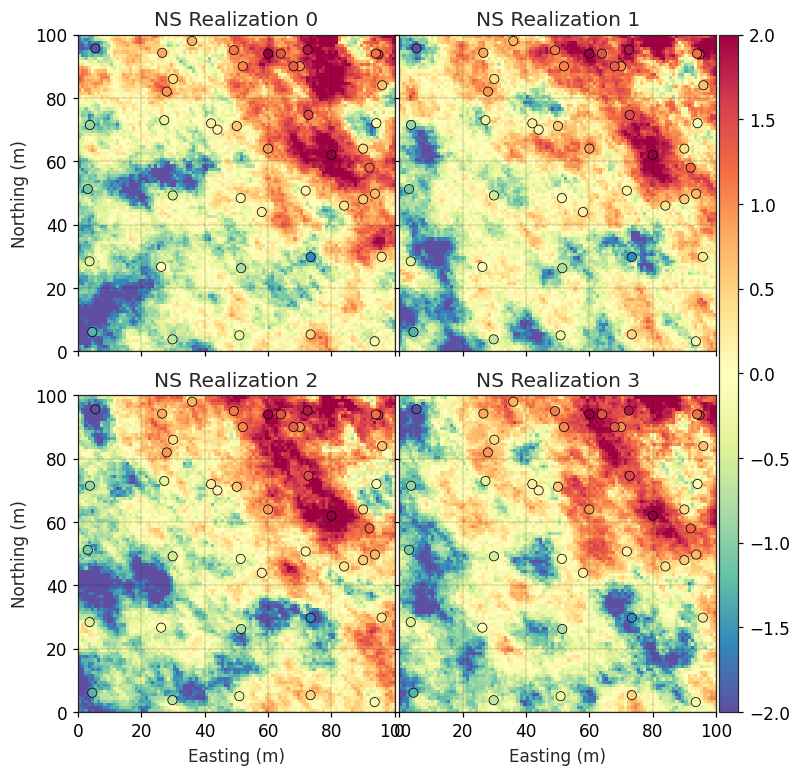

In [21]:
plot_realizations(ns_cache, ns_var.col, "NS")

Invert the Gaussian transformation to original units:

In [22]:
cache = nscore.inverse_transform_sim(
    ns_cache, ns_var.col, rmsp.SimCache(len(grid)), var.col
)

Visualize some realizations of the original variable:

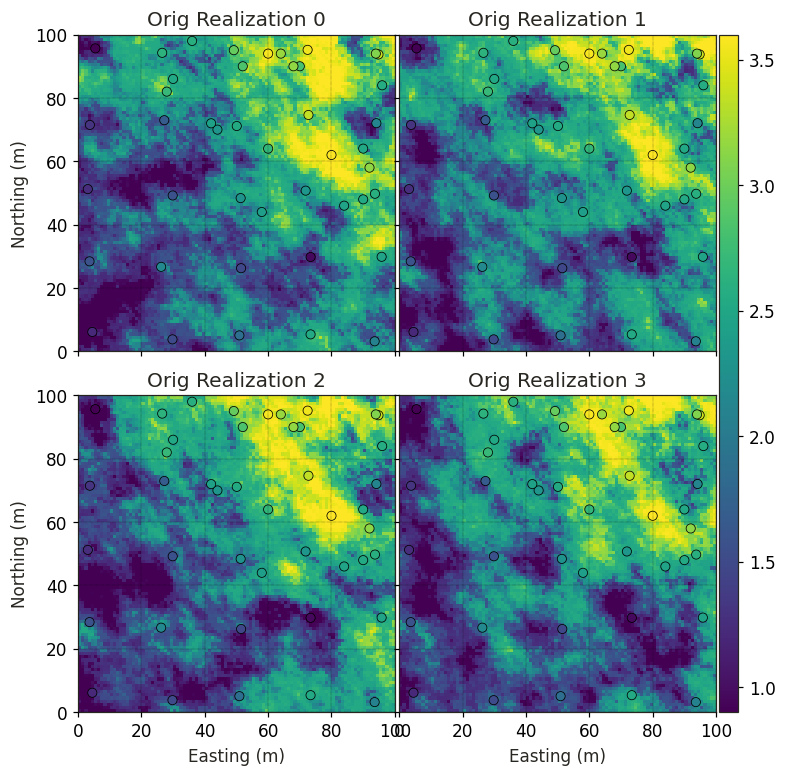

In [23]:
plot_realizations(cache, var.col, "Orig")

---

## Checking

Distribution checking:

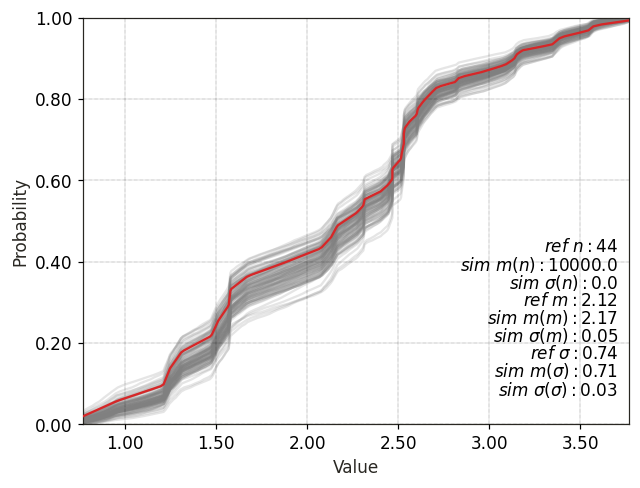

In [24]:
sim_unistats = [rmsp.UniStats(real[var.col]) for _, real in cache.iter_realizations()]
refstats = rmsp.UniStats(samples[var.col], samples["wts"])
fig, ax = refstats.cdfplot_checkreals(sim_unistats, xlabel=var.col, mod_alpha=0.2)

Calculate the variogram of the realizations and the data in original units before comparing.

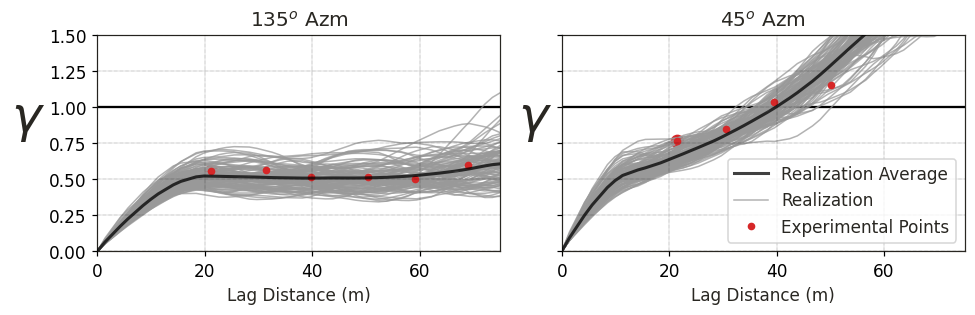

In [25]:
expvario0 = calc_model_varios(var.col, plot=False)[0]
grid_searches = [
    rmsp.ExpVarioSearchGrid(major, 0.0, 2.0 * np.arange(50)),
    rmsp.ExpVarioSearchGrid(minor, 0.0, 2.0 * np.arange(75)),
]
grid_expvario = rmsp.ExpVario().calculate_sim(
    cache, var.col, grid_searches, griddef, permit_standardized=True
)

fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for i, (ax, azm) in enumerate(zip(axes, [major, minor])):
    grid_expvario.plot_reals(
        i, title=f"{azm}$^o$ Azm", ax=ax, xlim=(0, 75), ylim=(0, 1.5), alpha=0.75
    )
    expvario0.plot_draw(ax, azm=azm, ms=4, label="Experimental Points", c="C3")

axes[1].legend(loc=4)
plt.tight_layout()

Although trends are visually reproduced, check swath plot reproduction to ensure:

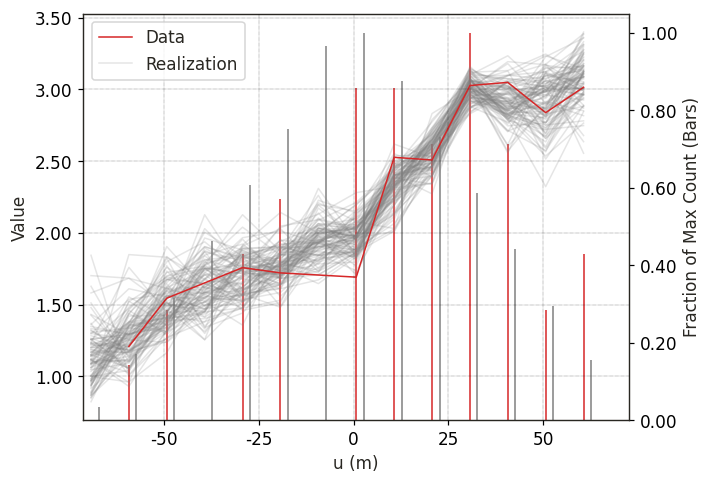

In [26]:
# Data swath
swath = rmsp.Swath(orient=minor, width=10)
swath.fit(samples, var.col)
fig, ax = swath.plot(c="C3", swath_label="Data")

# Realization swath
real = cache.get_real(0, griddef=griddef)
swath.fit(real, save_indices=True)
swath_kws = dict(c=".5", swath_kws={"alpha": 0.2, "zorder": -1})
swath.plot_draw(ax, swath_label="Realization", count_xoffset=2.0, **swath_kws)

# Remaining realizations
for ireal, real in cache.iter_realizations(
    griddef=griddef, reals=np.arange(1, num_real)
):
    swath.clone_on(real, use_indices=True).plot_draw(ax, count_lw=0, **swath_kws)

_ = ax.legend()

---
## Closing Comments

This notebook provided a worked example of key concepts introduced in [Trend Modeling and Modeling with a Trend](https://geostatisticslessons.com/lessons/trendmodeling), including:

- Modeling of a trend including optimization of smoothing
- Removal of a trend using stepwise conditional transformation with Gaussian mixture model parameterization
- Checking simulated realizations for reproduction of key representative properties, including non-stationarity

An important consideration for the holistic characterization of uncertainty, may be the parameterization and integration of trend uncertainty, which may be covered in a future lesson or companion notebook.

[Geostatistics Lessons](https://geostatisticslessons.com/) · [Notebook guide](README.md)